1. Data Integrity Validation
   - Image and annotation matching
   - Missing files
   - Duplicate references
   - Image readability

In [1]:
import os
import json
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PATH = "/kaggle/input/datasets/maram05ai/clevr-cogent-v1/CLEVR_CoGenT_v1.0"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset contents:", os.listdir(DATASET_PATH))

Dataset exists: True
Dataset contents: ['COPYRIGHT.txt', 'LICENSE.txt', 'README.txt', 'images', 'questions', 'scenes']


In [2]:
import os
import json

splits = ["trainA", "valA", "valB"]

for split in splits:

    print(f"\n{'='*45}")
    print(f"Checking {split}")
    print(f"{'='*45}")

    image_dir = os.path.join(
        DATASET_PATH, "images", split
    )

    annotation_file = os.path.join(
        DATASET_PATH, "scenes",
        f"CLEVR_{split}_scenes.json"
    )

    with open(annotation_file, "r") as f:
        data = json.load(f)

    scenes = data["scenes"]

    image_files = {
        file for file in os.listdir(image_dir)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    annotated_files = {
        scene["image_filename"] for scene in scenes
    }

    print("Number of annotations:", len(scenes))
    print("Number of images:", len(image_files))
    print("Unique annotated images:", len(annotated_files))

    print("Images without annotations:",
          len(image_files - annotated_files))

    print("Annotations without images:",
          len(annotated_files - image_files))

    print("Duplicate image references:",
          len(scenes) - len(annotated_files))


Checking trainA
Number of annotations: 70000
Number of images: 70000
Unique annotated images: 70000
Images without annotations: 0
Annotations without images: 0
Duplicate image references: 0

Checking valA
Number of annotations: 15000
Number of images: 15000
Unique annotated images: 15000
Images without annotations: 0
Annotations without images: 0
Duplicate image references: 0

Checking valB
Number of annotations: 15000
Number of images: 15000
Unique annotated images: 15000
Images without annotations: 0
Annotations without images: 0
Duplicate image references: 0


### Data Integrity Validation — Results

The image-to-annotation consistency check was performed
on trainA, valA, and valB.

Results:
- trainA: 70,000 images and 70,000 annotations.
- valA: 15,000 images and 15,000 annotations.
- valB: 15,000 images and 15,000 annotations.
- No missing images.
- No missing annotations.
- No duplicate image references.

Conclusion:
All three splits passed the image-to-annotation
consistency check.

In [3]:
import json
import os
from collections import Counter

splits = ["trainA", "valA", "valB"]

VALID_SHAPES = {"cube", "sphere", "cylinder"}

VALID_COLORS = {
    "gray", "red", "blue", "green",
    "brown", "purple", "cyan", "yellow"
}

for split in splits:

    annotation_file = os.path.join(
        DATASET_PATH,
        "scenes",
        f"CLEVR_{split}_scenes.json"
    )

    with open(annotation_file, "r") as f:
        scenes = json.load(f)["scenes"]

    shapes = Counter()
    colors = Counter()

    invalid_shapes = []
    invalid_colors = []
    missing_attributes = []

    total_objects = 0

    for scene in scenes:
        for obj in scene["objects"]:

            total_objects += 1

            shape = obj.get("shape")
            color = obj.get("color")

            if shape not in VALID_SHAPES:
                invalid_shapes.append(shape)

            if color not in VALID_COLORS:
                invalid_colors.append(color)

            if shape is None or color is None:
                missing_attributes.append(obj)

            shapes[shape] += 1
            colors[color] += 1

    print(f"\n{'='*45}")
    print(f"Annotation Validation: {split}")
    print(f"{'='*45}")

    print("Total objects:", total_objects)
    print("Shape distribution:", dict(shapes))
    print("Color distribution:", dict(colors))

    print("Invalid shapes:", len(invalid_shapes))
    print("Invalid colors:", len(invalid_colors))
    print("Missing attributes:", len(missing_attributes))


Annotation Validation: trainA
Total objects: 455024
Shape distribution: {'sphere': 152744, 'cylinder': 151544, 'cube': 150736}
Color distribution: {'yellow': 56830, 'cyan': 56951, 'gray': 56735, 'blue': 56456, 'brown': 57001, 'green': 57226, 'red': 57055, 'purple': 56770}
Invalid shapes: 0
Invalid colors: 0
Missing attributes: 0

Annotation Validation: valA
Total objects: 97900
Shape distribution: {'cube': 31871, 'sphere': 33315, 'cylinder': 32714}
Color distribution: {'gray': 12250, 'brown': 12018, 'red': 12232, 'cyan': 12277, 'blue': 12140, 'purple': 12522, 'green': 12363, 'yellow': 12098}
Invalid shapes: 0
Invalid colors: 0
Missing attributes: 0

Annotation Validation: valB
Total objects: 97193
Shape distribution: {'sphere': 32363, 'cylinder': 32380, 'cube': 32450}
Color distribution: {'green': 12317, 'cyan': 12086, 'yellow': 12086, 'purple': 12086, 'red': 12245, 'gray': 12159, 'brown': 12104, 'blue': 12110}
Invalid shapes: 0
Invalid colors: 0
Missing attributes: 0


## Shape-Color Combination Validation

In [4]:
import os
import json
import pandas as pd

splits = ["trainA", "valA", "valB"]

combination_tables = {}
combination_sets = {}

for split in splits:

    annotation_file = os.path.join(
        DATASET_PATH,
        "scenes",
        f"CLEVR_{split}_scenes.json"
    )

    with open(annotation_file, "r") as f:
        scenes = json.load(f)["scenes"]

    combinations = []

    for scene in scenes:
        for obj in scene["objects"]:
            combinations.append({
                "shape": obj["shape"],
                "color": obj["color"]
            })

    df = pd.DataFrame(combinations)

    table = pd.crosstab(
        df["shape"],
        df["color"]
    )

    combination_tables[split] = table
    combination_sets[split] = set(
        zip(df["shape"], df["color"])
    )

    print(f"\n{'='*50}")
    print(f"Shape-Color Combinations: {split}")
    print(f"{'='*50}")

    print(table)
    print("\nNumber of observed combinations:",
          len(combination_sets[split]))

# Compare Condition B against Condition A
seen_combinations = combination_sets["trainA"]
b_combinations = combination_sets["valB"]

unseen_combinations = b_combinations - seen_combinations

print("\n" + "="*50)
print("UNSEEN COMBINATIONS IN VALB")
print("="*50)

for shape, color in sorted(unseen_combinations):
    count = combination_tables["valB"].loc[shape, color]
    print(f"{shape:10s} + {color:10s}: {count:,}")

print("\nTotal unseen combinations:",
      len(unseen_combinations))


Shape-Color Combinations: trainA
color      blue  brown   cyan   gray  green  purple    red  yellow
shape                                                             
cube      37341  37819      0  37634      0       0      0   37942
cylinder      0      0  37820      0  38130   37633  37961       0
sphere    19115  19182  19131  19101  19096   19137  19094   18888

Number of observed combinations: 16

Shape-Color Combinations: valA
color     blue  brown  cyan  gray  green  purple   red  yellow
shape                                                         
cube      8008   7875     0  8033      0       0     0    7955
cylinder     0      0  8092     0   8253    8270  8099       0
sphere    4132   4143  4185  4217   4110    4252  4133    4143

Number of observed combinations: 16

Shape-Color Combinations: valB
color     blue  brown  cyan  gray  green  purple   red  yellow
shape                                                         
cube         0      0  8044     0   8225    7997  81

### Shape-Color Combination Validation

The observed shape-color combinations were analyzed
across trainA, valA, and valB.

Key findings:
- trainA contains 16 observed combinations.
- valA contains the same 16 combinations as trainA.
- valB contains 16 combinations, including 8 combinations
  absent from trainA.

The unseen combinations consist of:
- Four cube-color combinations:
  red, green, purple, and cyan.
- Four cylinder-color combinations:
  gray, blue, brown, and yellow.

All eight unseen combinations are present in valB,
with 64,830 objects in total.

The remaining 32,363 objects in valB are spheres,
whose shape-color combinations were already observed
during training.

Conclusion:
Only the eight specified cube and cylinder combinations
will be considered unseen during evaluation.
The entire valB split will not be treated as unseen data.

## 4. Image Integrity Validation

This section verifies that image files are readable and
that their dimensions and formats are consistent across
the selected dataset splits.

In [5]:
import os
from PIL import Image
from collections import Counter
from tqdm.notebook import tqdm

splits = ["trainA", "valA", "valB"]

image_validation_results = {}

for split in splits:

    image_dir = os.path.join(
        DATASET_PATH, "images", split
    )

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    corrupted_images = []
    image_dimensions = Counter()
    image_formats = Counter()

    for filename in tqdm(image_files, desc=f"Checking {split}"):

        image_path = os.path.join(image_dir, filename)

        try:
            with Image.open(image_path) as img:
                img.verify()

            # Reopen to inspect image properties
            with Image.open(image_path) as img:
                image_dimensions[img.size] += 1
                image_formats[img.format] += 1

        except Exception as e:
            corrupted_images.append({
                "filename": filename,
                "error": str(e)
            })

    image_validation_results[split] = {
        "total_images": len(image_files),
        "corrupted_images": len(corrupted_images),
        "dimensions": image_dimensions,
        "formats": image_formats
    }

    print(f"\n{'='*45}")
    print(f"Image Integrity: {split}")
    print(f"{'='*45}")

    print("Total images:", len(image_files))
    print("Corrupted images:", len(corrupted_images))
    print("Image dimensions:", dict(image_dimensions))
    print("Image formats:", dict(image_formats))

Checking trainA:   0%|          | 0/70000 [00:00<?, ?it/s]


Image Integrity: trainA
Total images: 70000
Corrupted images: 0
Image dimensions: {(480, 320): 70000}
Image formats: {'PNG': 70000}


Checking valA:   0%|          | 0/15000 [00:00<?, ?it/s]


Image Integrity: valA
Total images: 15000
Corrupted images: 0
Image dimensions: {(480, 320): 15000}
Image formats: {'PNG': 15000}


Checking valB:   0%|          | 0/15000 [00:00<?, ?it/s]


Image Integrity: valB
Total images: 15000
Corrupted images: 0
Image dimensions: {(480, 320): 15000}
Image formats: {'PNG': 15000}


## Object Extraction Strategy

The dataset provides object-level scene annotations, including object attributes and projected pixel coordinates. However, the pixel coordinates represent object centers rather than bounding boxes.

Therefore, an object extraction strategy must be established and visually validated before generating the final object-level dataset.

The extraction method should aim to:
- Capture the complete target object.
- Minimize background and neighboring-object interference.
- Preserve the object's visual attributes, especially shape and color.
- Maintain consistent extraction criteria across all dataset splits.

In [7]:
import os
import json

# Load trainA scene annotations
train_scenes_path = os.path.join(
    DATASET_PATH,
    "scenes",
    "CLEVR_trainA_scenes.json"
)

with open(train_scenes_path, "r") as f:
    train_scenes = json.load(f)

# Inspect one object
sample_scene = train_scenes["scenes"][0]
sample_object = sample_scene["objects"][0]

print("Available object attributes:")
for key, value in sample_object.items():
    print(f"{key}: {value}")

Available object attributes:
pixel_coords: [131, 173, 9.2485990524292]
size: large
color: yellow
material: metal
shape: sphere
3d_coords: [0.044448722153902054, -2.6995933055877686, 0.699999988079071]
rotation: 303.2391460924107


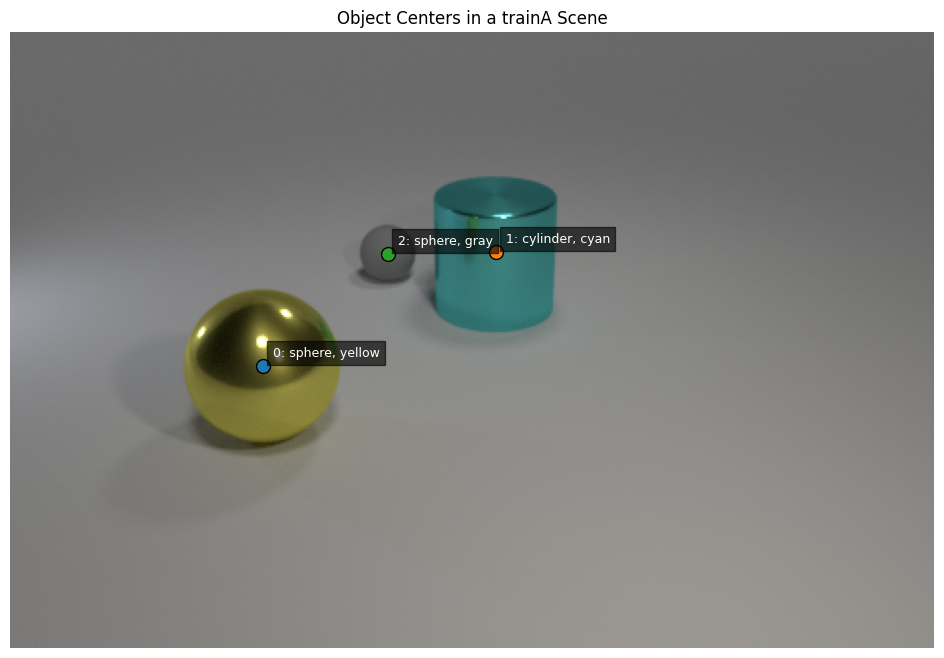

In [8]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Select one scene
sample_scene = train_scenes["scenes"][0]

# Load corresponding image
image_filename = sample_scene["image_filename"]
image_path = os.path.join(DATASET_PATH, "images", "trainA", image_filename)

image = Image.open(image_path)

# Display image and object centers
plt.figure(figsize=(12, 8))
plt.imshow(image)

for i, obj in enumerate(sample_scene["objects"]):
    x, y, depth = obj["pixel_coords"]

    plt.scatter(x, y, s=100, edgecolors="black")
    plt.text(
        x + 5, y - 5,
        f'{i}: {obj["shape"]}, {obj["color"]}',
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.6)
    )

plt.title("Object Centers in a trainA Scene")
plt.axis("off")
plt.show()